# Part 2 — Data Quality & Panel
## Notebook 03. Automated FDIC data-quality audit and bank-quarter panel

**Research objective.** Construct a validated, typed bank-quarter panel for 1984Q1–2026Q2; identify the source-data limitations relevant to bank-risk analysis; and document terminal events without introducing future outcome information into the predictor panel.

**Source contract.** The explicitly selected Google Drive experiment must contain **both** a verified acquisition stage and a verified storage stage. This notebook neither queries FDIC again nor uses a historical run ID. Its inputs are the immutable Part 1 artifacts.

**Outputs.** Quarter-partitioned Parquet panel; data-quality, coverage, reporting-gap, failure-linkage, terminal-event and availability audits; four summary figures; a SHA-256 manifest; and an independently verified `quality_panel` stage. These results remain on Google Drive, not in GitHub.

### 1. Select the experiment and restore the Part 2 source revision

The acquisition code revision is locked by `experiment_config.lock.json`. This stage records its own 40-character Git commit, allowing the same verified dataset to be analysed by a separately identified source revision. A previously completed Part 2 stage is always reopened at its originally recorded commit; published outputs are not overwritten.

In [1]:
from pathlib import Path
import json
import re
import shutil
import subprocess
import sys
from google.colab import drive

drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive/BFT65B_11230945")
active_path = DRIVE_ROOT / "control" / "active_experiment.json"
assert active_path.is_file(), "Run Notebooks 01 and 02 first; no active experiment exists"
pointer = json.loads(active_path.read_text(encoding="utf-8"))
EXPERIMENT_ID = pointer["experiment_id"]
experiment_dir = DRIVE_ROOT / "experiments" / EXPERIMENT_ID
part1_config = json.loads((experiment_dir / "experiment_config.lock.json").read_text(encoding="utf-8"))
assert part1_config["experiment_id"] == EXPERIMENT_ID
PART1_COMMIT = part1_config["git_commit"]

REPO_DIR = Path("/content/bft65b_code")
if REPO_DIR.exists():
    shutil.rmtree(REPO_DIR)
subprocess.run(["git", "clone", "--quiet",
    "https://github.com/NguyenDuong58/11230945-NguyenBaDuong.git", str(REPO_DIR)], check=True)

previous_manifest = experiment_dir / "quality_panel" / "part2_manifest.json"
if previous_manifest.is_file():
    PART2_COMMIT = json.loads(previous_manifest.read_text(encoding="utf-8"))["code_commit"]
    assert re.fullmatch(r"[0-9a-f]{40}", PART2_COMMIT)
    subprocess.run(["git", "-C", str(REPO_DIR), "checkout", "--quiet", PART2_COMMIT], check=True)
else:
    PART2_COMMIT = subprocess.check_output(
        ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True).strip()

assert subprocess.check_output(
    ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], text=True).strip() == PART2_COMMIT
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                str(REPO_DIR / "requirements.txt")], check=True)
sys.path.insert(0, str(REPO_DIR / "src"))
print("Experiment:", EXPERIMENT_ID)
print("Acquisition code commit:", PART1_COMMIT)
print("Quality-panel code commit:", PART2_COMMIT)
print("Code directory:", REPO_DIR)

Mounted at /content/drive
Experiment: experiment_20261116T115513Z_d23d2b10
Acquisition code commit: c5bad10b9199fe163ae7e1e1c1d9029a4be0c470
Quality-panel code commit: 68751e16b01fc7d984ed8c918dd059277830a105
Code directory: /content/bft65b_code


### 2. Execute unit and integration tests

The test gate includes source-policy tests, synthetic Parquet panel construction, checksum-tampering tests and the unchanged Part 1 tests. **Every test must run with zero failures, errors and skips**. Tests with synthetic FDIC-shaped records do not replace full-sample verification.

In [2]:
import xml.etree.ElementTree as ET

TEST_XML = Path("/content/bft65b_part2_tests.xml")
subprocess.run([sys.executable, "-m", "pytest", "-q", "-rs",
                "--junitxml", str(TEST_XML), str(REPO_DIR / "tests")],
               cwd=REPO_DIR, check=True)
suites = ET.parse(TEST_XML).getroot().findall(".//testsuite")
assert suites, "No test suites were recorded"
result = {name: sum(int(s.get(name, 0)) for s in suites)
          for name in ("tests", "failures", "errors", "skipped")}
assert result["failures"] == result["errors"] == result["skipped"] == 0, result
print("Full test gate: PASSED", result)

Full test gate: PASSED {'tests': 124, 'failures': 0, 'errors': 0, 'skipped': 0}


### 3. Verify the selected Part 1 source and storage stages

Both published stages must pass the experiment registry and the acquisition source contract. The storage validation SHA-256 is recorded as an additional dependency of Part 2; the registry's direct parent for `quality_panel` is `acquisition`.

In [3]:
from fdic_pipeline.project_flow import get_active, resolve_stage, stage_dir
from fdic_pipeline.workflow import acquisition_contract
from fdic_pipeline.panel import _check_root, panel_schema, EXCLUDED_PREDICTOR_FIELDS

ACTIVE = get_active(DRIVE_ROOT)
assert ACTIVE["experiment_id"] == EXPERIMENT_ID
ACQUISITION = resolve_stage(DRIVE_ROOT, "acquisition")
STORAGE = resolve_stage(DRIVE_ROOT, "storage")
SOURCE_DIR, SOURCE_CHECK, STORAGE_HASH = _check_root(DRIVE_ROOT)
assert SOURCE_CHECK["quarters"] == 170
assert STORAGE["validation"]["success"] is True
assert ACQUISITION["validation"]["success"] is True
print("Part 1 input contract: PASSED")
print("Verified quarters:", SOURCE_CHECK["quarters"])
print("Financials observations:", SOURCE_CHECK["financial_rows"])
print("Failures reference rows:", SOURCE_CHECK["failures_rows"])
print("Institutions reference rows:", SOURCE_CHECK["institutions_rows"])
print("Acquisition manifest SHA-256:", SOURCE_CHECK["manifest_sha256"])
print("Storage validation SHA-256:", STORAGE_HASH)

Part 1 input contract: PASSED
Verified quarters: 170
Financials observations: 1682616
Failures reference rows: 4117
Institutions reference rows: 27835
Acquisition manifest SHA-256: 9b1f943b156e5a0006b194cd06211461878a9c2018440db791b87d6d6a6d2f61
Storage validation SHA-256: 060c41128b11f6247b871b37957017fbc1f3539af02f8b17aded5a6e42fa4266


### 4. Prespecify source-data quality and temporal-availability policies

The source Financials values remain unchanged. Financial ratios and balance-sheet inconsistencies are flagged for review rather than automatically winsorised. Financial reports without a positive, finite asset denominator are excluded from the clean analytical panel and retained in a separate quarantine audit.

`ASSUMED_AVAILABLE_FROM = REPDTE + 90 calendar days` is a documented scenario, **not an actual historical release timestamp**. Observed bank failures and institutional exits remain in separate audit tables; the panel contains neither retrospective status nor the target label.

In [4]:
from fdic_pipeline.data_quality import QUALITY_RULES, TERMINAL_CLASSES
from fdic_pipeline.panel import AVAILABILITY_SCENARIOS

ASSUMED_LAG_DAYS = 90
PANEL_SCHEMA = panel_schema()
assert not (set(PANEL_SCHEMA.names) & EXCLUDED_PREDICTOR_FIELDS)
print("Source Financials columns:", SOURCE_CHECK["financial_fields"])
print("Panel columns:", len(PANEL_SCHEMA.names))
print("Current-quarter quality flags:", len(QUALITY_RULES))
print("Retrospective terminal classes:", len(TERMINAL_CLASSES))
print("Assumed data lag (days):", ASSUMED_LAG_DAYS)
print("Availability sensitivity scenarios:", AVAILABILITY_SCENARIOS)
print("Retrospective predictor fields: ABSENT")

Source Financials columns: 33
Panel columns: 48
Current-quarter quality flags: 10
Retrospective terminal classes: 9
Assumed data lag (days): 90
Availability sensitivity scenarios: (30, 90, 180)
Retrospective predictor fields: ABSENT


### 5. Construct the clean panel and full quality audit

The builder verifies each source file's checksum, Arrow schema, row count and reporting-quarter identity before processing it. It processes the 170 quarters in chronological order, writes typed Snappy Parquet partitions, generates audit tables and figures, then verifies its own outputs. In the event of an interrupted **unpublished** stage, the notebook removes only its incomplete `quality_panel` directory and rebuilds it. A published stage is always verified read-only.

In [5]:
from fdic_pipeline.project_flow import HandoffError

QUALITY_DIR = stage_dir(DRIVE_ROOT, "quality_panel")
LOG_FILE = ACTIVE["experiment_dir"] / "run_logs" / "part2_quality_panel.log"
try:
    PREVIOUSLY_PUBLISHED = resolve_stage(DRIVE_ROOT, "quality_panel")
except HandoffError as exc:
    if "has not passed verification" not in str(exc):
        raise
    PREVIOUSLY_PUBLISHED = None

if PREVIOUSLY_PUBLISHED is None:
    command = [
        sys.executable, str(REPO_DIR / "run_data_quality.py"), "build",
        "--drive-root", str(DRIVE_ROOT),
        "--code-commit", PART2_COMMIT,
        "--availability-lag-days", str(ASSUMED_LAG_DAYS),
        "--replace-incomplete", "--log-file", str(LOG_FILE),
    ]
    subprocess.run(command, cwd=REPO_DIR, check=True)
else:
    print("Previously published quality-panel stage detected; verifying existing results")

QUALITY_STAGE = resolve_stage(DRIVE_ROOT, "quality_panel")
assert QUALITY_STAGE["validation"]["success"] is True
print("Quality-panel stage:", QUALITY_STAGE["status"])
print("Stage directory:", QUALITY_DIR)
print("Persistent log:", LOG_FILE)

Quality-panel stage: PASSED
Stage directory: /content/drive/MyDrive/BFT65B_11230945/experiments/experiment_20261116T115513Z_d23d2b10/quality_panel
Persistent log: /content/drive/MyDrive/BFT65B_11230945/experiments/experiment_20261116T115513Z_d23d2b10/run_logs/part2_quality_panel.log


### 6. Inspect source reconciliation, missingness, anomalies and reporting gaps

Check the exact accounting identity **raw Financials = clean panel + quarantined observations**. Missingness is reported for all 33 source fields and by reporting year, while screening rules are counted separately. Reporting gaps are derived from consecutive observed source reports for each `CERT` rather than treating a missing quarter as a zero-valued record.

In [6]:
import csv
from IPython.display import display, Markdown

def display_evidence_table(title: str, relative_file: str, max_rows: int = 12) -> None:
    with (QUALITY_DIR / relative_file).open(newline="", encoding="utf-8") as handle:
        rows = list(csv.DictReader(handle))
    display(Markdown("**" + title + "**"))
    if not rows:
        display(Markdown("No qualifying observations."))
        return
    columns = list(rows[0])
    chosen = rows[:max_rows]
    def fmt(s):
        return str(s).replace("|", "&#124;").replace("\n", " ")
    table = " | ".join(columns) + "\n" + " | ".join(["---"] * len(columns))
    table += "\n" + "\n".join(" | ".join(fmt(r[k]) for k in columns) for r in chosen)
    display(Markdown(table))
    if len(rows) > max_rows:
        print(f"Showing {max_rows} of {len(rows)} rows; complete audit remains on Drive")

MANIFEST = json.loads((QUALITY_DIR / "part2_manifest.json").read_text(encoding="utf-8"))
print("Raw Financials:", MANIFEST["raw_rows"])
print("Clean bank-quarter panel:", MANIFEST["panel_rows"])
print("Quarantined observations:", MANIFEST["quarantined_rows"])
print("Distinct Financials CERT:", MANIFEST["source_certificates"])
print("Distinct CERT retained in panel:", MANIFEST["clean_certificates"])
print("Reporting intervals with missing quarters:", MANIFEST["reporting_gap_intervals"])
assert MANIFEST["raw_rows"] == MANIFEST["panel_rows"] + MANIFEST["quarantined_rows"]
display_evidence_table("Highest field missingness", "audits/field_missingness.csv", 12)
display_evidence_table("Quality rule frequencies", "audits/quality_rules.csv", 12)

Raw Financials: 1682616
Clean bank-quarter panel: 1682616
Quarantined observations: 0
Distinct Financials CERT: 24064
Distinct CERT retained in panel: 24064
Reporting intervals with missing quarters: 33


**Highest field missingness**

FIELD | TOTAL_ROWS | MISSING_ROWS | MISSING_PCT
--- | --- | --- | ---
CERT | 1682616 | 0 | 0.0
REPDTE | 1682616 | 0 | 0.0
STNAME | 1682616 | 191 | 0.011351
ASSET | 1682616 | 0 | 0.0
DEP | 1682616 | 1 | 5.9e-05
DEPDOM | 1682616 | 1 | 5.9e-05
EQ | 1682616 | 4148 | 0.246521
BRO | 1682616 | 16761 | 0.996127
CHBAL | 1682616 | 1 | 5.9e-05
SC | 1682616 | 1 | 5.9e-05
LNLSGR | 1682616 | 1 | 5.9e-05
LNLSNET | 1682616 | 1 | 5.9e-05

Showing 12 of 33 rows; complete audit remains on Drive


**Quality rule frequencies**

RULE | FLAGGED_ROWS | DISTINCT_FLAGGED_CERT
--- | --- | ---
DQ_NEGATIVE_DEPOSITS | 0 | 0
DQ_DEPOSITS_GT_ASSETS | 6204 | 1561
DQ_NEGATIVE_GROSS_LOANS | 32 | 11
DQ_GROSS_LOANS_GT_ASSETS | 761 | 127
DQ_NONCURRENT_GT_GROSS_LOANS | 6 | 6
DQ_NEGATIVE_EQUITY | 15659 | 2837
DQ_NEGATIVE_CASH_BALANCES | 2 | 1
DQ_CASH_GT_ASSETS | 1 | 1
DQ_EXTREME_ROA | 244 | 56
DQ_EXTREME_ROE | 11710 | 4218

### 7. Review failure linkage, terminal evidence and availability uncertainty

These audits are **retrospective evaluation resources**, not current-quarter features. `failure_counts_by_period.csv` reports source failure events dated within two predefined calendar windows; those values do not establish the model's final development or test population, which will be set in Part 4. Undated failures, missing `CERT`, conflicting events and unresolved discontinuations remain separately identifiable.

In [7]:
print("Terminal class counts:")
for name, count in MANIFEST["terminal_class_counts"].items():
    print(f"  {name}: {count}")
print("Failures without a valid CERT:", MANIFEST["failure_missing_cert_rows"])
display_evidence_table("Dated failures by illustrative calendar period", "audits/failure_counts_by_period.csv", 10)
display_evidence_table("Historical availability-lag scenarios", "audits/availability_scenarios.csv", 5)

Terminal class counts:
  ambiguous_failure_events: 42
  ambiguous_failure_evidence: 0
  confirmed_failure: 2775
  documented_other_exit: 16313
  inconsistent_event_timing: 422
  inconsistent_institution_end_date: 5
  right_censored: 4306
  unparseable_institution_end_date: 0
  unresolved_discontinuation: 201
Failures without a valid CERT: 488


**Dated failures by illustrative calendar period**

PERIOD | START | END | DATED_FAILURE_SOURCE_ROWS | DISTINCT_DATED_CERT | DISTINCT_DATED_CERT_IN_FINANCIALS | DATED_ROWS_MISSING_CERT | DISTINCT_CERT_DATE_PAIRS
--- | --- | --- | --- | --- | --- | --- | ---
1984Q1–2006Q4 | 1984-01-01 | 2006-12-31 | 2710 | 2677 | 2655 | 0 | 2710
2008Q1–2014Q4 | 2008-01-01 | 2014-12-31 | 520 | 520 | 520 | 0 | 520

**Historical availability-lag scenarios**

ASSUMED_LAG_DAYS | SOURCE_REPORTS | NOT_AVAILABLE_BY_STUDY_END | ASSUMPTION_ONLY
--- | --- | --- | ---
30 | 1682616 | 4313 | True
90 | 1682616 | 4313 | True
180 | 1682616 | 8666 | True

### 8. Display the automated quality evidence figures

Figures present source field missingness, annual bank-quarter coverage, retrospective terminal classes and current-quarter anomaly flags. The original figures and CSV tables are stored with SHA-256 fingerprints in Google Drive.

**Field Missingness**

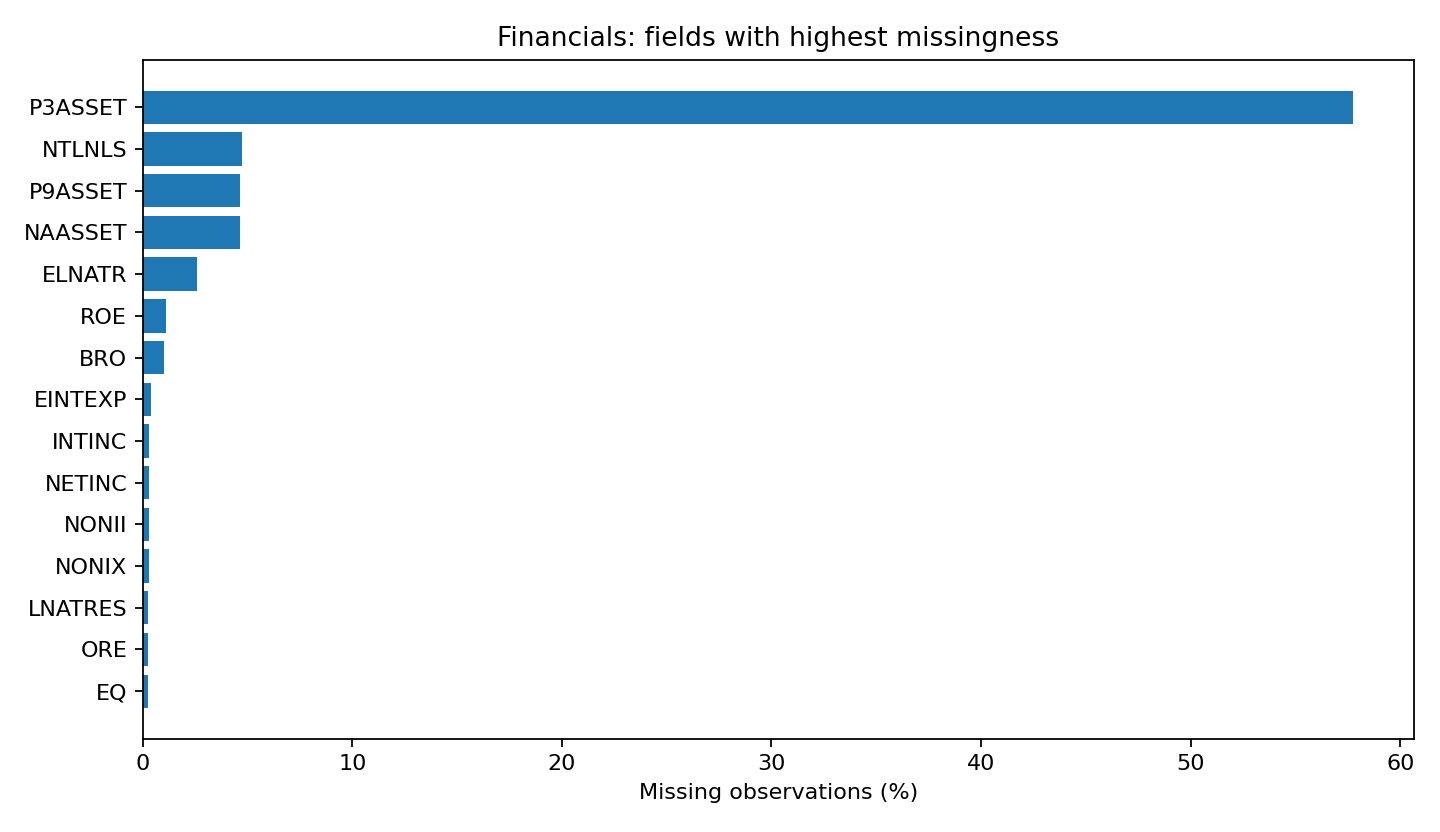

**Annual Coverage**

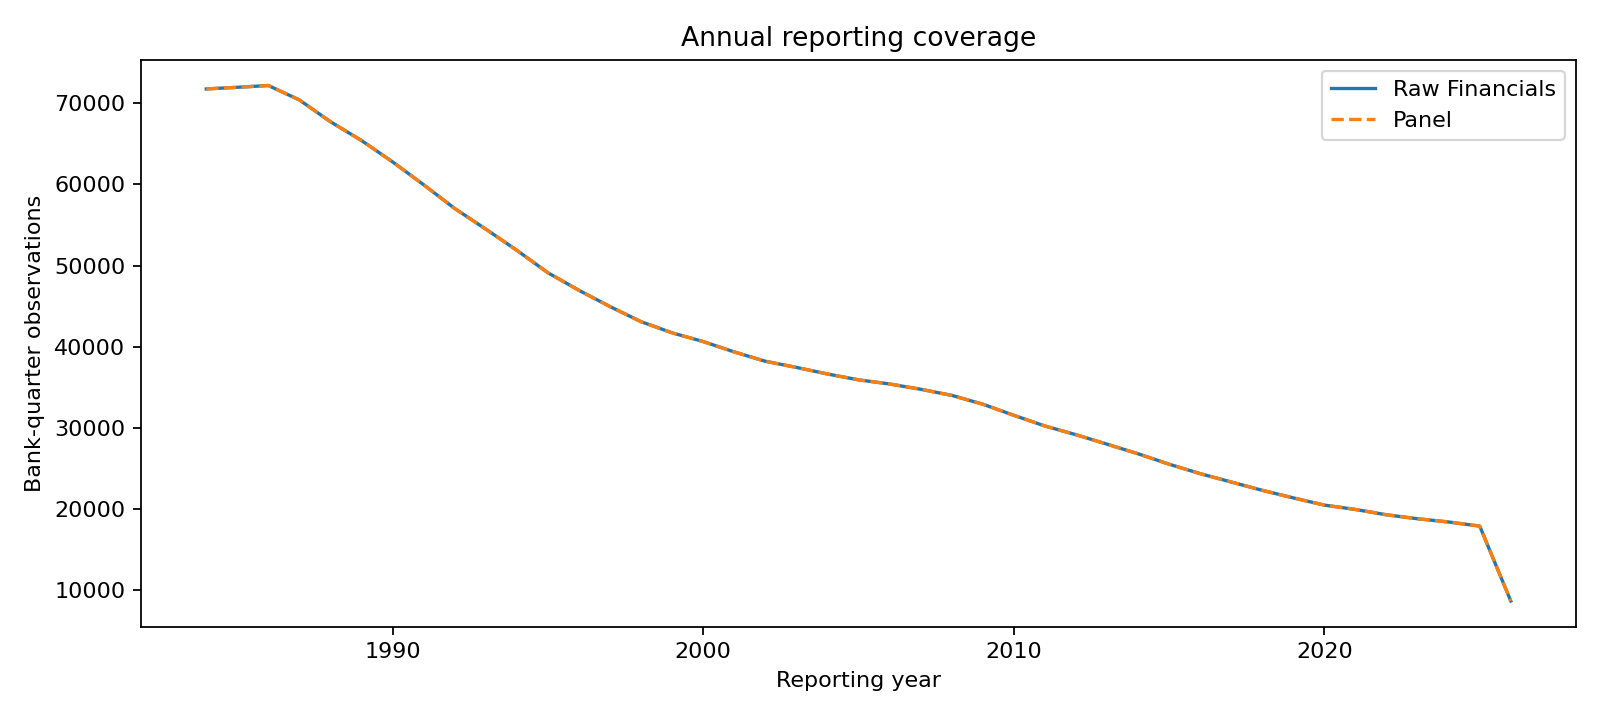

**Terminal Classes**

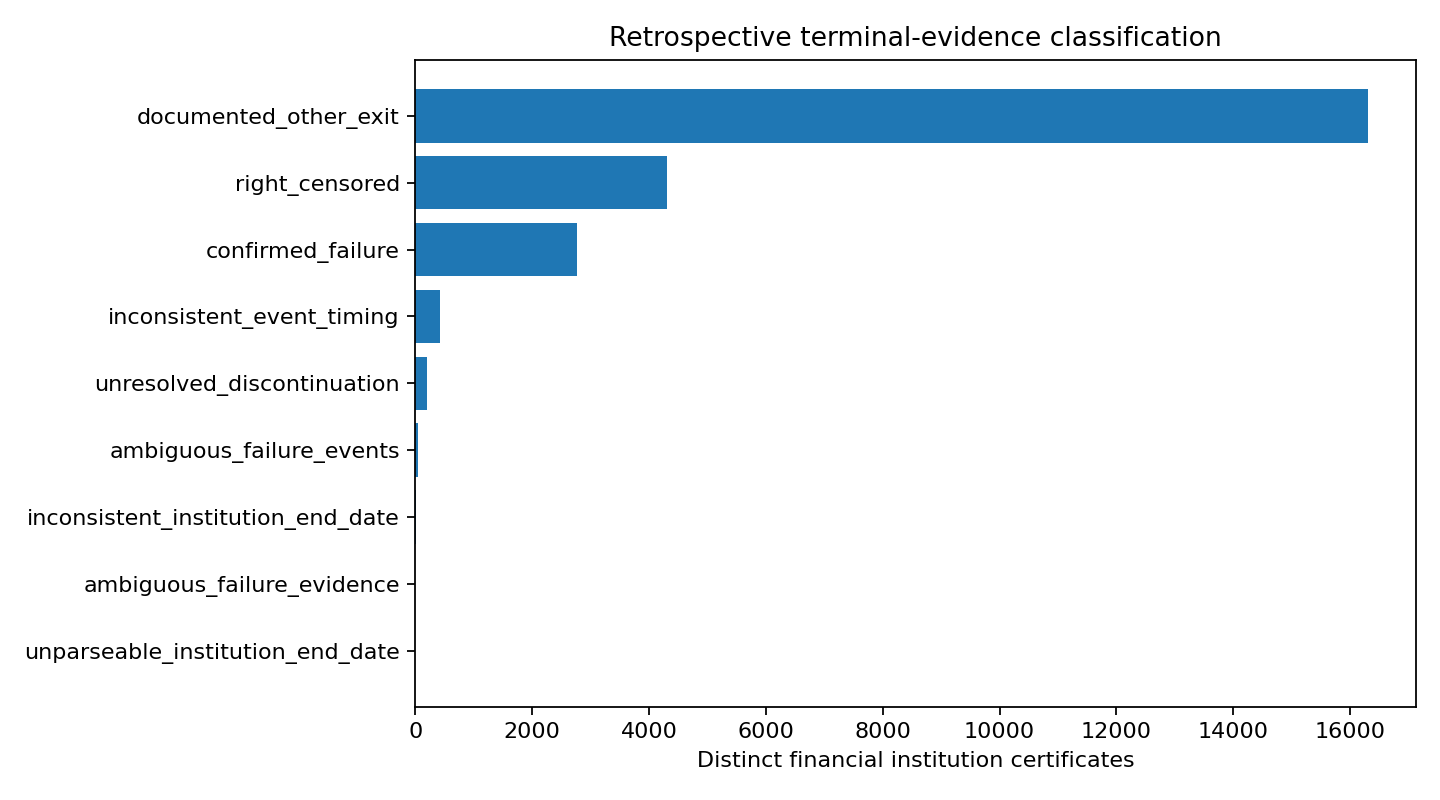

**Rule Counts**

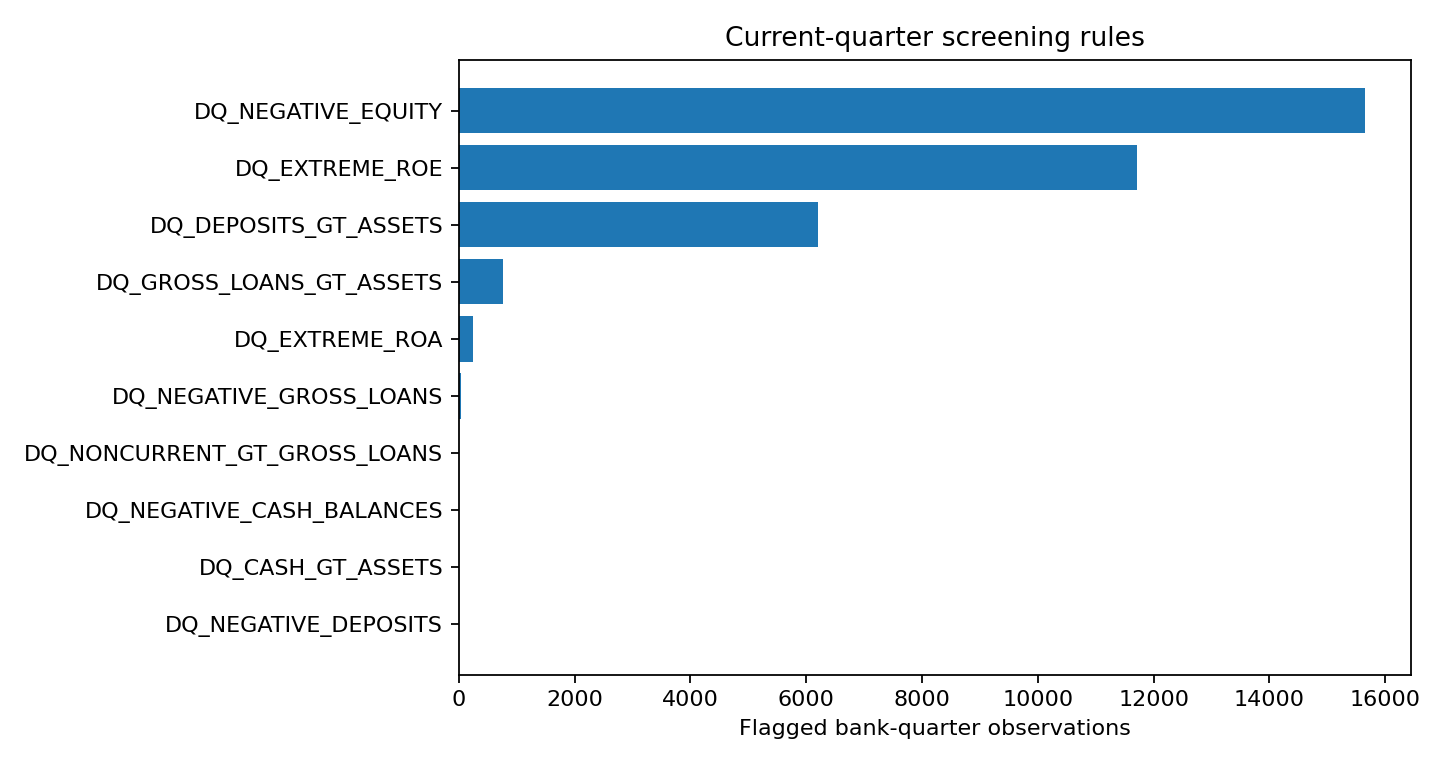

In [8]:
from IPython.display import Image

for relative in (
    "figures/field_missingness.png",
    "figures/annual_coverage.png",
    "figures/terminal_classes.png",
    "figures/rule_counts.png",
):
    display(Markdown("**" + Path(relative).stem.replace("_", " ").title() + "**"))
    display(Image(filename=str(QUALITY_DIR / relative), width=790))

### 9. Independently verify the published Part 2 artifact

The read-only verifier checks the published stage lineage, Part 1 source-file checksums, all 170 output Parquet files, schema, observation reconciliation and every saved audit artifact. Verification cannot overwrite a prior result. It rejects a modified source, Parquet partition, audit table or stage validation file.

In [9]:
from fdic_pipeline.panel import verify_project_stage

VERIFIED = verify_project_stage(DRIVE_ROOT)
assert VERIFIED["success"] is True
assert VERIFIED["quarters"] == 170
assert VERIFIED["source_rows"] == SOURCE_CHECK["financial_rows"]
assert VERIFIED["source_rows"] == VERIFIED["panel_rows"] + VERIFIED["quarantined_rows"]
assert VERIFIED["storage_verification_sha256"] == STORAGE_HASH
assert VERIFIED["predictor_event_columns_absent"] is True
assert VERIFIED["actual_publication_times_verified"] is False
assert VERIFIED["code_commit"] == PART2_COMMIT
print("Part 2: PASSED")
print("Financials source rows:", VERIFIED["source_rows"])
print("Clean panel rows:", VERIFIED["panel_rows"])
print("Quarantined rows:", VERIFIED["quarantined_rows"])
print("Verified quarters:", VERIFIED["quarters"])
print("Audit evidence artifacts:", VERIFIED["audit_artifacts_verified"])
print("Verified source-to-output lineage: PASSED")

Part 2: PASSED
Financials source rows: 1682616
Clean panel rows: 1682616
Quarantined rows: 0
Verified quarters: 170
Audit evidence artifacts: 17
Verified source-to-output lineage: PASSED


### 10. Establish the verified Part 3 input contract

Part 3 reads the fixed `quality_panel/panel/` Parquet directory after resolving `quality_panel` from the experiment registry, and checks its manifest and SHA-256 validation evidence. The terminal-event and failure-linkage audit tables are **not** supplied as predictors to the processing engines or model feature pipeline.

In [10]:
FINAL_STAGE = resolve_stage(DRIVE_ROOT, "quality_panel")
assert FINAL_STAGE["status"] == "PASSED"
assert FINAL_STAGE["validation"]["part2_manifest_sha256"] == VERIFIED["part2_manifest_sha256"]
print("Part 3 Parquet source:", QUALITY_DIR / "panel")
print("Part 2 manifest:", QUALITY_DIR / "part2_manifest.json")
print("Part 2 verification:", QUALITY_DIR / "part2_validation.json")
print("Quality-panel Git commit:", PART2_COMMIT)
print("Handoff state: PASSED")

Part 3 Parquet source: /content/drive/MyDrive/BFT65B_11230945/experiments/experiment_20261116T115513Z_d23d2b10/quality_panel/panel
Part 2 manifest: /content/drive/MyDrive/BFT65B_11230945/experiments/experiment_20261116T115513Z_d23d2b10/quality_panel/part2_manifest.json
Part 2 verification: /content/drive/MyDrive/BFT65B_11230945/experiments/experiment_20261116T115513Z_d23d2b10/quality_panel/part2_validation.json
Quality-panel Git commit: 68751e16b01fc7d984ed8c918dd059277830a105
Handoff state: PASSED
